# Kinetic model
Oligomerization on Ni-NU-1000 with the corrected driver (`scripts/km_common.py`, see `docs/model.md`).
`km_common` switches the working directory to `data/` when imported.

In [1]:
import sys
sys.path.insert(0, '../scripts')
import km_common as km
import matplotlib.pyplot as plt
import pandas as pd

def show(dist, title):
    d = dist.dropna(subset=['probability'])
    plt.bar(d.n, d.probability); plt.xlabel('n'); plt.ylabel('share of olefins'); plt.title(f"{title}  <n> = {km.mean_length(dist):.2f}")
    plt.show()

## One case: 340 K, 1 bar, batch, infinite crystal

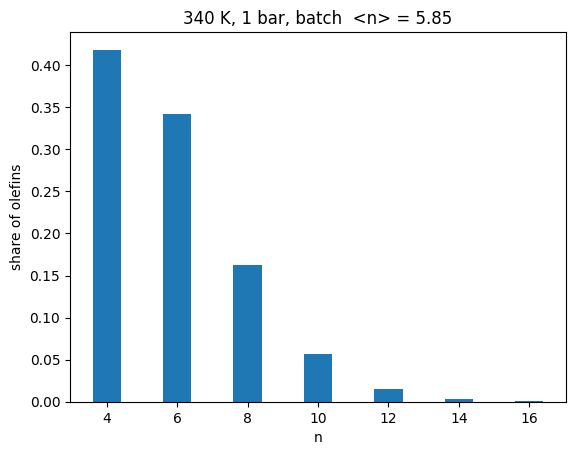

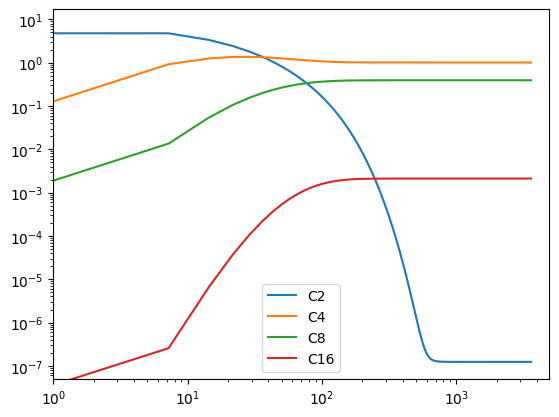

In [2]:
dist, ts = km.run_case(T=340, p=1, counting='pore', barriers='tetra', mode='batch', particle_nm=None, hours=1, n_steps=500)
show(dist, '340 K, 1 bar, batch')
ts[['C2', 'C4', 'C8', 'C16']].plot(logx=True, logy=True, xlim=(1, None));

## Temperature scan

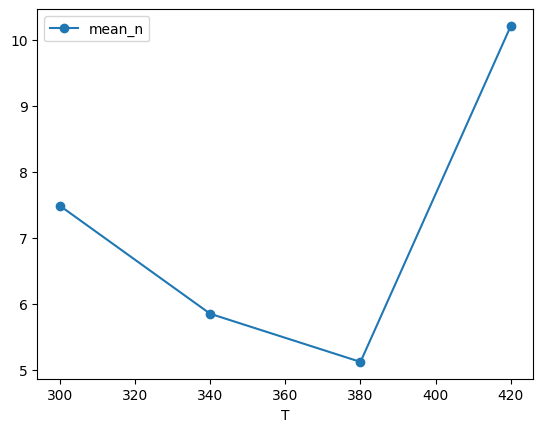

In [3]:
rows = [(T, km.mean_length(km.run_case(T=T, p=1, mode='batch', particle_nm=None, hours=1, n_steps=300)[0])) for T in (300, 340, 380, 420)]
pd.DataFrame(rows, columns=['T', 'mean_n']).plot(x='T', y='mean_n', marker='o');

## Pressure counting
`pore`: pressure through the pore concentration; `gas`: ideal-gas ethylene in the free energies (flow only). Both count it once.

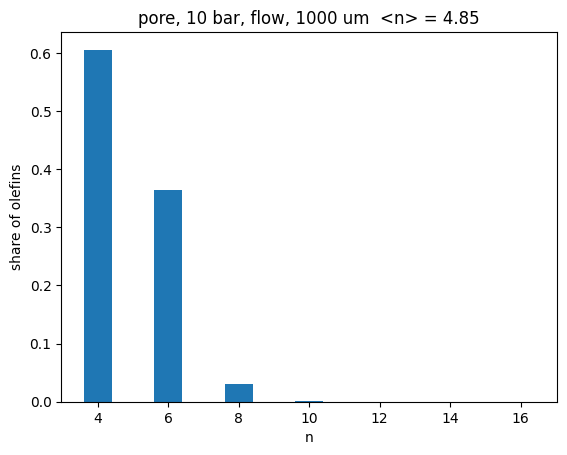

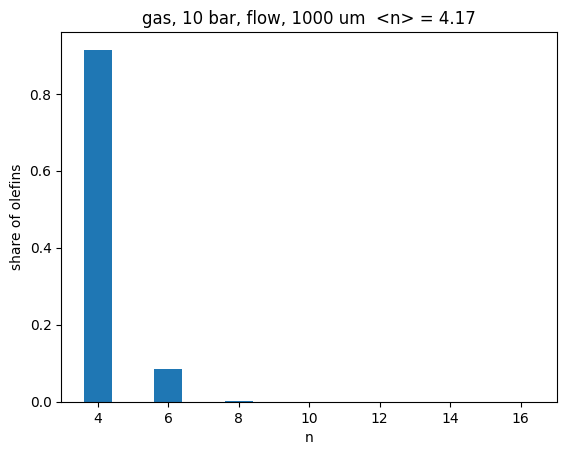

In [4]:
for counting in ('pore', 'gas'):
    dist, _ = km.run_case(T=340, p=10, counting=counting, mode='flow', particle_nm=1e6, hours=1, n_steps=300)
    show(dist, f'{counting}, 10 bar, flow, 1000 um')

## Barrier sets
`tetra` one set for all chain lengths (default); `individual` own barrier per step; `legacy` original list (eliminations shifted by one).

In [5]:
for b in ('tetra', 'individual', 'legacy'):
    dist, _ = km.run_case(T=340, p=1, barriers=b, mode='batch', particle_nm=None, hours=1, n_steps=300)
    print(b, round(km.mean_length(dist), 2))

tetra 5.85
individual 4.19
legacy 6.43


## Product crowding
With ethylene in the pore, released olefins are penalized; `pocket` is the recommended variant.

In [6]:
for crowding in (None, 'pocket'):
    dist, _ = km.simulate(T=300, p=50, mode='batch', particle_nm=None, model='corrected', hours=1, n_steps=300,
                          elim_map='tetra', **({'crowding': crowding} if crowding else {}))
    print(crowding, round(km.mean_length(dist), 2))

None 7.49
pocket 14.82


## Network validity
The reduced network holds only where the ethylene-bound state is the resting state.

In [7]:
for T in (300, 420, 540):
    ok, gap, msgs = km.network_consistency(T, 1.0)
    print(T, 'K', 'ok' if ok else f'not valid (gap {gap:.1f} kJ/mol)')

300 K ok
420 K ok
540 K not valid (gap 19.1 kJ/mol)
